# **CH04 - 분류(2)**

# **03 앙상블 학습**

- 여러 개의 분류기(Classifier)를 생성하고 그 예측을 결합함으로써 보다 정확한 예측 도출하는 기법
- 정형 데이터 분류에 좋음 
- 앙상블 알고리즘의 대표 : 랜덤포레스트, 그래디언트 부스팅

앙상블의 유형  
1)보팅(Voting) 
 - 여러 개의 분류기가 투표를 통해 최종 예측 결과를 결정
 - 서로 다른 알고리즘을 가진 분류기를 결합  
 - 선형 회귀, k 최근접 이웃, 서포트 벡터 머신
   
2)배깅(Bagging)   
 -  여러 개의 분류기가 투표를 통해 최종 예측 결과를 결정  
 -  같은 알고리즘을 가진 분류기들 기반, 데이터 샘플링이 다름  
 -  랜덤 포레스트 알고리즘, 단일 결정 트리  
 -  중첩 허용

3)부스팅(Boosting)  
 - 개별 Classifier에게 데이터를 샘플링해서 추출하는 방식  
 - 가중치 부여  
 - 그래디언트 부스트, XGBoost, LightGBM  

4)스태깅
 - 여러 가지 다른 모델의 예측 결괏값을 다시 학습 데이터로 만들어서 다른 모델(메타 모델)로 재학습시켜 결과를 예측



## **보팅 유형-하드 보팅과 소프트 보팅**

하드보팅
- 다수결 원칙과 비슷
- 다수의 분류기가 결정한 예측값을 최종 보팅 결괏값으로 선정

소프트 보팅
- 분류기들의 레이블 값 결정 확률을 모두 더하고 평균을 내서 확률이 가장 높은 레이블 값을 최종 보팅 결괏값

## **보팅 분류기**

- 사이킷런은 보팅 방식의 앙상블을 구현한 VotingClassifier 클래스를 제공

  
아래에서 위스콘신 유방암 데이터 세트 예측
- 사이킷런은 load_breast_cancer() 함수를 통해 자체에서 위스콘신 유방암 데이터 세트를 생성
- 로지스틱 회귀와 KNN 기반으로 보팅 분류기 만들기 


In [1]:
import pandas as pd

from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

cancer = load_breast_cancer()

data_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
data_df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


로지스틱 회귀와 KNN을 기반으로 하여 소프트 보팅 방식으로 새롭게 보팅 분류기를 만들기  
- VotingClassifier 클래스는 주요 생성 인자로 estimators와 voting 값을 입력받음
- estimators는  리스트 값으로 보팅에 사용될 여러 개의 Classifier 객체들을 튜플 형식으로 입력받음
- voting은 hard, soft 둘 중 선택

In [2]:
# 개별 모델은 로지스틱 회귀와 KNN임.
lr_clf = LogisticRegression(solver='liblinear')
knn_clf = KNeighborsClassifier(n_neighbors=8)

# 개별 모델을 소프트 보팅 기반의 앙상블 모델로 구현한 분류기
vo_clf = VotingClassifier( estimators=[('LR', lr_clf), ('KNN', knn_clf)], voting='soft')

X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, test_size=0.2, random_state=156)

# VotingClassifier 학습/예측/평가
vo_clf.fit(X_train, y_train)
pred = vo_clf.predict(X_test)
print('Voting 분류기 정확도: {0:.4f}'.format(accuracy_score(y_test, pred)))

# 개별 모델의 학습/예측/평가
classifiers = [lr_clf, knn_clf]
for classifier in classifiers:
  classifier.fit(X_train, y_train)
  pred = classifier.predict(X_test)
  class_name=classifier.__class__.__name__
  print('{0} 정확도: {1:.4f}'.format(class_name, accuracy_score(y_test, pred)))

Voting 분류기 정확도: 0.9561
LogisticRegression 정확도: 0.9474
KNeighborsClassifier 정확도: 0.9386


# **04 랜덤 포레스트**

- 배깅방법 적용
- 비교적 빠른 수행 속도
- 기반 알고리즘은 결정 트리
- 여러 개의 결정 트리 분류기가 전체 데이터에서 배깅 방식으로 각자의 데이터를 샘플링해 개별적으로 학습을 수행한 뒤 최종적으로 모든 분류기가 보팅을 통해 예측 결정
- 부트스트랩:복원추출
- 사이킷런은 RandomForestClassifier 클래스를 통해 지원



사용자 행동 인식 데이터 세트를 RandomForestClassifier를 이용해 예측하기
- random_state=0 설정으로 재수행할때마다 동일한 예측 결과 출력하도록 함
- get_human_dataset() : 사용자 행동 데이터의 데이터프레임을 반환 

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import warnings
warnings.filterwarnings('ignore')


def get_new_feature_name_df(old_feature_name_df):
    feature_dup_df = pd.DataFrame(data=old_feature_name_df.groupby('column_name').cumcount(), columns=['dup_cnt'])
    new_feature_name_df = pd.merge(old_feature_name_df.reset_index(drop=True), feature_dup_df.reset_index(drop=True), left_index=True, right_index=True)
    new_feature_name_df['column_name'] = new_feature_name_df.apply(lambda x: f"{x['column_name']}_{int(x['dup_cnt'])}" if x['dup_cnt'] > 0 else x['column_name'], axis=1)
    return new_feature_name_df

    
def get_human_dataset():
  feature_name_df=pd.read_csv(r'C:\Users\user\OneDrive\문서\UCI HAR Dataset\UCI HAR Dataset\features.txt', sep='\s+', header=None, names=['column_index', 'column_name'])
  new_feature_name_df = get_new_feature_name_df(feature_name_df)
  feature_name = new_feature_name_df.iloc[:, 1].values.tolist()
  X_train = pd.read_csv(r'C:\Users\user\OneDrive\문서\UCI HAR Dataset\UCI HAR Dataset\train\X_train.txt',sep=r'\s+', names=feature_name)
  X_test = pd.read_csv(r'C:\Users\user\OneDrive\문서\UCI HAR Dataset\UCI HAR Dataset\test\X_test.txt', sep=r'\s+', names=feature_name)
  y_train = pd.read_csv(r'C:\Users\user\OneDrive\문서\UCI HAR Dataset\UCI HAR Dataset\train\y_train.txt',sep=r'\s+', header=None, names=['action'])
  y_test = pd.read_csv(r'C:\Users\user\OneDrive\문서\UCI HAR Dataset\UCI HAR Dataset\test\y_test.txt', sep=r'\s+', header=None, names=['action'])
  return X_train, X_test, y_train, y_test

# 결정 트리에서 사용한 get_human_dataset()를 이용해 학습/테스트용 DataFrame 반환
X_train, X_test, y_train, y_test = get_human_dataset()

# 랜덤 포레스트 학습 및 별도의 테스트 세트로 예측 성능 평가
rf_clf = RandomForestClassifier(random_state=0, max_depth=8)
rf_clf.fit(X_train, y_train)
pred = rf_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred)
print('랜덤 포레스트 정확도: {0:.4f}'.format(accuracy))

랜덤 포레스트 정확도: 0.9196


## **랜덤 포레스트 하이퍼 파라미터 및 튜닝**

- 트리 기반의 앙상블 알고리즘은 하이퍼 파라미터가 너무 많아서 튜닝 시간이 오래 걸림
- n_estimators: 랜덤 포레스트에서 결정 트리의 개수를 지정, 디폴트는 10개
- max_features: 결정 트리에 사용된 maxjeatures 파라미터와 같으나,RandomForestClassifier의 기본 max_features는 ‘None’이 아니라 ‘auto’, 즉 ‘sqrt’와 같음.
- max_depth나 min_samples_leat, min_samples_split와 같이 결정 트리에서 과적합을 개선하기 위해 사용되는 파라미터가 랜덤 포레스트에도 똑같이 적용

 GridSearchCV를 이용해 랜덤 포레스트의 하이퍼 파라미터를 튜닝하기

In [8]:
from sklearn.model_selection import GridSearchCV

params = {
    'max_depth': [8, 16, 24],
    'min_samples_leaf': [1, 6, 12],
    'min_samples_split': [2, 8, 16]
}

# RandomForestClassifier 객체 생성 후 GridSearchCV 수행
rf_clf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
grid_cv = GridSearchCV(rf_clf, param_grid=params, cv=2, n_jobs=-1)
grid_cv.fit(X_train, y_train)

print('최적 하이퍼 파라미터:\n', grid_cv.best_params_)
print('최고 예측 정확도: {0:.4f}'.format(grid_cv.best_score_))

최적 하이퍼 파라미터:
 {'max_depth': 16, 'min_samples_leaf': 6, 'min_samples_split': 2}
최고 예측 정확도: 0.9165


별도의 테스트 데이터 세트에서 예측 성능을 측정해보기 

In [9]:
rf_clf1 = RandomForestClassifier(n_estimators=100, min_samples_leaf=6, max_depth=16, min_samples_split=2, random_state=0)
rf_clf1.fit(X_train, y_train)
pred = rf_clf1.predict(X_test)
print('예측 정확도: {0:.4f}'.format(accuracy_score(y_test, pred)))

예측 정확도: 0.9260


피처 중요도를 막대그래프로 시각화

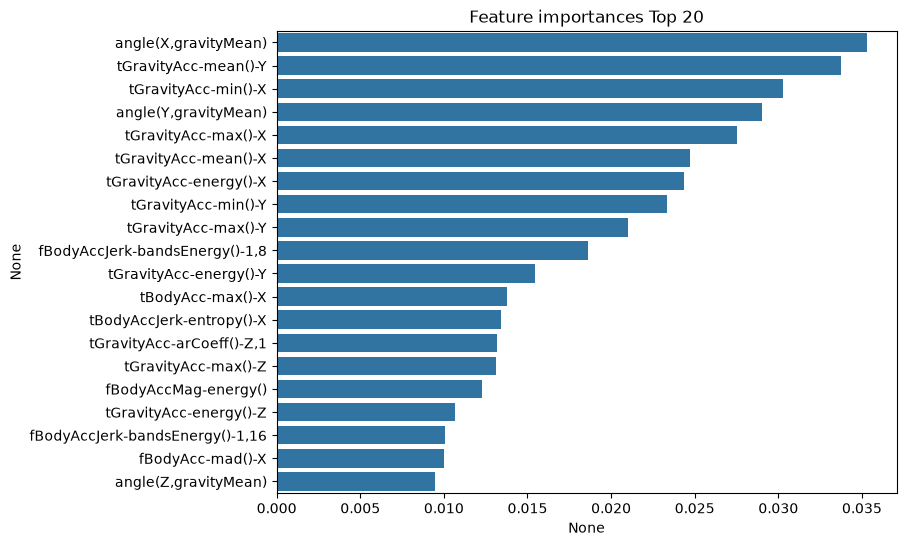

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

ftr_importances_values = rf_clf1.feature_importances_
ftr_importances = pd.Series(ftr_importances_values, index=X_train.columns)
ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]

plt.figure(figsize=(8,6))
plt.title('Feature importances Top 20')
sns.barplot(x=ftr_top20, y=ftr_top20.index)
plt.show()

# **05 GBM(Gradient Boosting Machine)**

부스팅 방법:여러 개의 약한 학습기(weak learner)를 순차적으로 학습-예측하면서 잘못 예측한 데이터에 가중치 부여를 통해 오류를 개선해 나가면서 학습하는 방식  

- 에이다 부스트(AdaBoost):오류 데이터에 가중치를 부여하면서 부스팅 수행
- GBM:가중치 업데이트를 오류를 최소화할 수 있도록 경사 하강법을 이용하여 부스팅 수행

GBM
- 분류, 회귀 가능
- 사이킷런은 GBM 기반의 분류를 위해 GradientBoostingClassifier 클래스를 제공

아래에서 사이킷런의 GBM을 이용해 사용자 행동 데이터 세트를 예측 분류해보기

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
import time
import warnings
warnings.filterwarnings('ignore')

X_train, X_test, y_train, y_test = get_human_dataset()

# GBM 수행 시간 측정을 위함. 시작 시간 설정.
start_time = time.time()

gb_clf = GradientBoostingClassifier(random_state=0)
gb_clf.fit(X_train, y_train)
gb_pred = gb_clf.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)

print('GBM 정확도: {0:.4f}'.format(gb_accuracy))
print('GBM 수행 시간: {0:.1f} 초'.format(time.time() - start_time))

기본 하이퍼 파라미터만으로 앞의 랜덤포레스트보다 나은 예측 성능, 그러나 수행 시간이 오래 걸림 

## **GBM 하이퍼 파라미터소개**

n_estimators, max_depth, max_features와 같은 트리 기반 자체의 파라미터와 더불어

- loss:경사 하강법에서 사용할 비용함수 지정(기본값 devianve)
- learning_rate:GBM이 학습 진행할 때마다 적용하는 학습률, Weak learner가 순차적0 루 오류 값을 보정해 나가는 데 적용하는 계수, 0~1 사이의 값을 지정할 수 있으며 기본값은 0.1 
- n_estimators:weak learner의 개수
- subsample:weak learner가 학습에 사용하는 데이터의 샘플링 비율

# **06 XGBoost(eXtra Gradient Boost)**

- GBM 기반이지만, 느린 수행 시간과 과적합 규제 부재 등 문제 해결
- 병렬 CPU 환경에서 병렬 학습 가능
- 뛰어난 예측 성능
- Tree pruning으로 더 이상 긍정 이득이 없는 분할을 가지치기
- 자체 내장된 교차 검증
- 결손값 자체 처리
- xgboost 패키지 내에는 XGBoost 전용의 파이썬 패키지와 사이킷런과 호환되는 래퍼용 XGBoost 가 함께 존재
- 사이킷런 래퍼 클래스는 XGBClassifier와 XGBRegressor 이용: 사이킷런 프로세스 사용 가능(원래 사이킷런에서 제공되지 않았음)
-  초기의 독자적인 XGBoost 프레임워크 기반의 XGBoost를 파이썬 래퍼 XGBoost 모 
듈, 사이킷런과 연동되는 모듈을 人｝이킷런 래퍼 XGBoost 모듈이라고 지칭

In [19]:
#pip install xgboost==1.5.0
!pip install --upgrade setuptools xgboost

   ---------------------------------------- 0.0/818.2 kB ? eta -:--:--
   ------------------------- -------------- 524.3/818.2 kB 2.4 MB/s eta 0:00:01
   ---------------------------------------- 818.2/818.2 kB 2.3 MB/s  0:00:00
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 2.5 MB/s eta 0:00:20
   - -------------------------------------- 1.3/48.9 MB 2.5 MB/s eta 0:00:20
   - -------------------------------------- 1.8/48.9 MB 2.4 MB/s eta 0:00:20
   - -------------------------------------- 2.4/48.9 MB 2.4 MB/s eta 0:00:20
   -- ------------------------------------- 2.9/48.9 MB 2.4 MB/s eta 0:00:20
   -- ------------------------------------- 3.4/48.9 MB 2.4 MB/s eta 0:00:19
   --- ------------------------------------ 3.9/48.9 MB 2.4 MB/s eta 0:00:19
   --- ------------------------------------ 4.5/48.9 MB 2.4 MB/s eta 0:00:19
   ---- --------

In [20]:
import xgboost as xgb
from xgboost import XGBClassifier

In [21]:
import xgboost

print(xgboost.__version__)

3.4.1


## **파이썬 래퍼 XGBoost 하이퍼 파라미터**

GBM과 유사한 하이퍼 파라미터에 더 추가된 형태  
파이썬 래퍼 XGBoost 모듈과 사이킷런 래퍼 XGBoost 모듈의 일부 하이퍼 파라미터는 약간 다르므로 이에 대한 주의가 필요   

## <파이썬 래퍼에 대한>

**일반 파라미터**
- 일반적으로 실행 시 스레드의 개수나 silent = 등의 선택을 위한 파라미터로서 디폴트 파라미터 값을 바꾸는 경우는 거의 없음
-  booster： gbtree(tree based model) 또는 gblinear( linear model) 선택. 디폴트는 gbtree
-  silent： 디폴트는 0이며, 출력 메시지를 나타내고 싶지 않을 경우 1로 설정
-  nthread： CPU의 실행 스레드 개수를 조정하며, 디폴트는 CPU의 전체 스레드를 다 사용

**부스터 파라미터**
- 트리 최적화, 부스팅, regularization 등과 관련 파라미터 등을 지칭
- eta[default=0.3, alias: learning_rate] : GBM의 학습률과 같은
- num_boost_rounds:GBM의 n_estimators와 같은
- min_chile_weight[default=1]:트리에서 추가적으로 가지를 나눌지를 결정하기 위해 필요한 데이터들의 weight 총합.
- gamma [default=0, alias： min_split_loss]： 트리의 리프 누드를 추가적으로 나눌지를 결정할 최소 손실 감소 값
- max_depth[default=6]： 트리 기반 알고리즘의 max_depth와 같은, 0을 지정하면 깊이에 제한 없음
- sub_sample[default=1]： GBM의 subsample과 동일
- colsample_bytree[default=l]： GBM의 max_features와 유사
- lambda [default=1, alias： reg_lambda]： L2 Regularization 적용 값
- alpha [default=0, alias： reg_alpha]： L1 Regularization 적용 값
- scale_pos_weight [default=1]： 특정 값으로 치우친 비대칭한 클래스로 구성된 데이터 세트의 균형을 유지

**태스크 파라미터**
- 학습 수행 시의 객체 함수, 평가를 위한 지표 등을 설정하는 파라미터
- objective： 최솟값을 가져야 할 손실 함수를 정의
- binary:logistic： 이진 분류일 때 적용
- multi：softmax： 다중 분류일 때 적용
- multi：softprob： multfeoftmax와 유사하나 개별 레이블 클래스의 해당되는 예측 확률을 반환
- eval_metric： 검증에 사용되는 함수를 정의 (rmse, mae, logloss, error, merror, mlogloss, auc) 

## **파이썬 래퍼 XGBoost 적용 - 위스콘신 유방암 예측**

xgboost 모듈을 로딩하고 xgb로 명명  
xgboost 패키지는 피처의 중요도를 시각화해주는 모듈인 plotjmportance를 함께 제공 
사이킷런에 내장된 load_breast_cancer()를 호출

In [22]:
import xgboost as xgb
from xgboost import plot_importance
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

dataset = load_breast_cancer()
features= dataset.data
labels = dataset.target

cancer_df = pd.DataFrame(data=features, columns=dataset.feature_names)
cancer_df['target']= labels
cancer_df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


타깃 레이블 값의 종류는 악성인 ‘malignant’가 0 값으로, 양성인 ‘benign’이 1 값  
레이블 값 분포 확인하기 

In [23]:
print(dataset.target_names)
print(cancer_df['target'].value_counts())

['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


위스콘신 유방암 데이터 세트의 80%를 학습용으로, 20%를 테스트용으로 추출한 뒤 이 80%의 학습용 데이터에서 90%를 최종 학습용, 10%를 검증용으로 분할
- 여기서 검증용 데이터 세트를 별도로 분할하는 이유는 XGBoost가 제공하는 기능인 검증 성능 평가와 조기 중단(early stopping)을 수행해 보기 위함
- cancer_df의 맨 마지막 칼럼이 레이블이므로 피처용 DataFrame은 cancer_df의 첫번째 칼럼에서 맨 마지막 두번째 칼럼까지를 :-1 슬라이싱으로 추출

In [24]:
# cancer_df에서 feature용 DataFrame과 Label용 Series 객체 추출
# 맨 마지막 칼럼이 Label임. Feature용 DataFrame은 cancer_df의 첫번째 칼럼에서 맨 마지막 두번째 칼럼까지를 :-1 슬라이싱으로 추출.
X_features = cancer_df.iloc[:, :-1]
y_label = cancer_df.iloc[:, -1]

# 전체 데이터 중 80%는 학습용 데이터, 20%는 테스트용 데이터 추출
X_train, X_test, y_train, y_test=train_test_split(X_features, y_label, test_size=0.2, random_state=156)

# 위에서 만든 X_train, y_train을 다시 쪼개서 90%는 학습과 10%는 검증용 데이터로 분리 (XGBoost가 제공하는 기능 수행해 보고자)
X_tr, X_val, y_tr, y_val=train_test_split(X_train, y_train, test_size=0.1, random_state=156)

print(X_train.shape, X_test.shape)
print(X_tr.shape, X_val.shape)
     

(455, 30) (114, 30)
(409, 30) (46, 30)


전체 569개의 데이터 세트에서 최종 학습용 409개, 검증용 46개, 테스트용 114개가 추출  

파이썬 래퍼 XGBoost는 사이킷런과 여러 가지 차이가 있지만, 먼저 눈에 띄는 차이는XGBoost만의 전용 데이터 객체인 DMatrix를 사용
- DMatrix는 넘파이, DataFrame, Series외에 libsvm txt 포맷 파일, xgboost 이진 버퍼 파일을 파라미터로 입력받아 변환

DataFrame 기반의 학습 데이터 세트와 테스트 데이터 세트를 DMatrix로 변환하는 예제

In [25]:
# 만약 구버전 XGBoost에서 DataFrame으로 DMatrix 생성이 안 될 경우 X_train.values로 넘파이 변환.
# 학습, 검증, 테스트용 DMatrix를 생성.
dtr = xgb.DMatrix(data=X_tr, label=y_tr)
dval = xgb.DMatrix(data=X_val, label=y_val)
dtest = xgb.DMatrix(data=X_test, label=y_test)

XGBoost의 하이퍼 파라미터를 설정하기
- 주로 딕셔너리 형태로 입력
- 트리 최대 깊이를 3, 학습률은 0.1, 예제 데이터가 0 또는 1 이진 분류이므로 목적함수는 이진 로지스틱으로 설정, 오류 함수의 평가 성능 지표는 logloss, 부스팅 반복 횟수는 400회로 설정

In [ ]:
params = { 'max_depth':3,
           'eta': 0.05,
           'objective':'binary:logistic',
           'eval_metric':'logloss'
          }
num_rounds = 400

위에 설정한 하이퍼 파라미터로 모델 학습시키기 

In [ ]:
# 학습 데이터 셋은 'train' 또는 평가 데이터 셋은 'eval'로 명기합니다.
eval_list = [(dtr, 'train'), (dval, 'eval')] # 또는 eval_list = [(dval, 'eval')] 만 명기해도 무방.

# 하이퍼 파라미터와 early stopping 파라미터를 train() 함수의 파라미터로 전달
xgb_model = xgb.train(params = params, dtrain=dtr, num_boost_round=num_rounds, early_stopping_rounds=50, evals=eval_list)
     

In [28]:
pred_probs = xgb_model.predict(dtest)
print('predict() 수행 결괏값을 10개만 표시, 예측 확률 값으로 표시됨')
print(np.round(pred_probs[:10], 3))

# 예측 확률이 0.5보다 크면 1, 그렇지 않으면 0으로 예측값 결정하여 List 객체인 preds에 저장
preds = [ 1 if x > 0.5 else 0 for x in pred_probs ]
print('예측값 10개만 표시:',preds[:10])

predict() 수행 결괏값을 10개만 표시, 예측 확률 값으로 표시됨
[0.933 0.006 0.687 0.123 0.974 0.999 0.998 0.998 0.996 0.001]
예측값 10개만 표시: [1, 0, 1, 0, 1, 1, 1, 1, 1, 0]


In [31]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

def get_clf_eval(y_test, pred, pred_proba):
    confusion = confusion_matrix(y_test, pred)
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc_auc = roc_auc_score(y_test, pred_proba)
    print('오차행렬')
    print(confusion)
    print('정확도:{0:.4f}, 정밀도:{1:.4f}, 재현율:{2:.4f}, F1:{3:.4f}, AUC:{4:.4f}'.format(accuracy, precision, recall, f1, roc_auc))

In [32]:
get_clf_eval(y_test, preds, pred_probs)

오차행렬
[[35  2]
 [ 2 75]]
정확도:0.9649, 정밀도:0.9740, 재현율:0.9740, F1:0.9740, AUC:0.9947


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

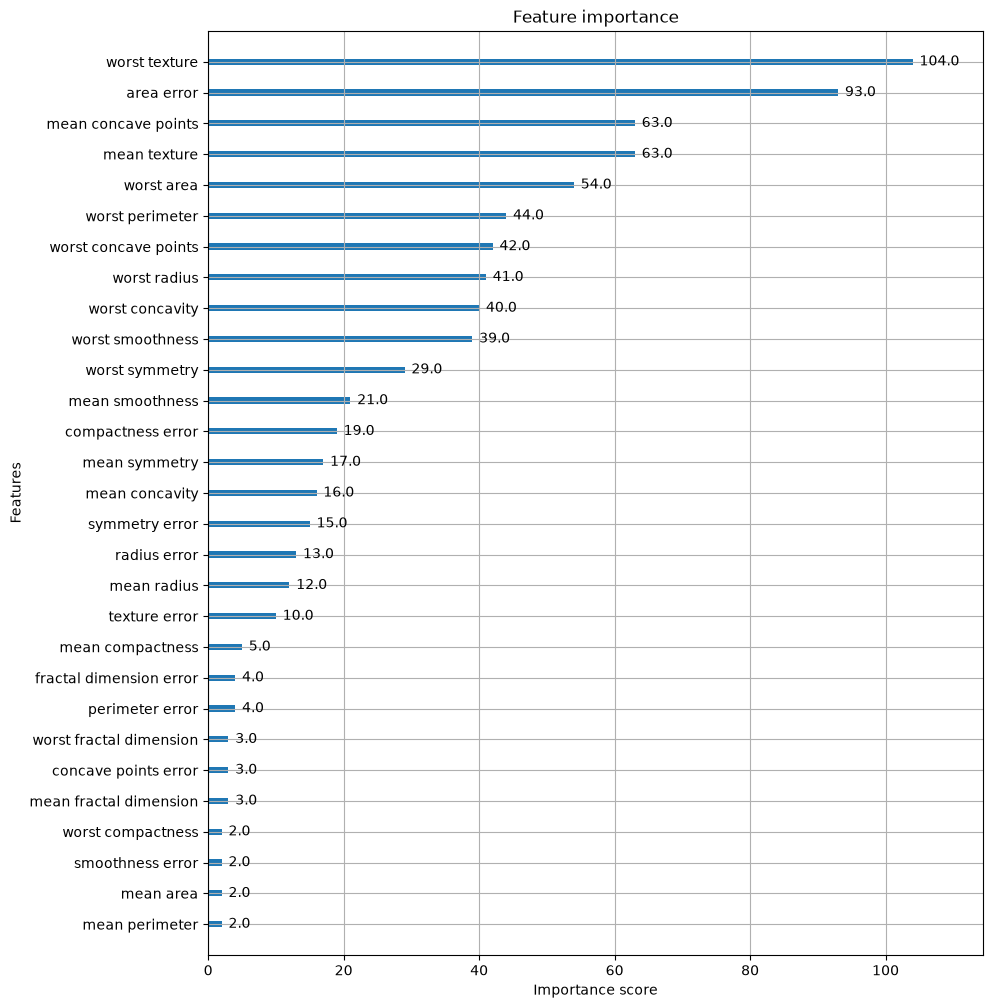

In [33]:
import matplotlib.pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 12))
plot_importance(xgb_model, ax=ax)

## **사이킷런 래퍼 XGBoost 개요 및 적용**

fit( )과 predict( )만으로 학습과 예측이 가능,GridSearchCV, Pipeline 등 사이킷런의 다른 유틸리티를 그대로 사용

In [34]:
# 사이킷런 래퍼 XGBoost 클래스인 XGBClassifier 임포트
from xgboost import XGBClassifier

# Warning 메시지를 없애기 위해 eval_metric 값을 XGBClassifier 생성 인자로 입력.
xgb_wrapper = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, eval_metric='logloss')
xgb_wrapper.fit(X_train, y_train, verbose=True)
w_preds = xgb_wrapper.predict(X_test)
w_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

In [35]:
get_clf_eval(y_test, w_preds, w_pred_proba)

오차행렬
[[35  2]
 [ 1 76]]
정확도:0.9737, 정밀도:0.9744, 재현율:0.9870, F1:0.9806, AUC:0.9958


In [36]:
from xgboost import XGBClassifier

xgb_wrapper = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, early_stopping_rounds=50, eval_metric='logloss')
evals = [(X_tr, y_tr), (X_val, y_val)]
xgb_wrapper.fit(X_tr, y_tr, eval_set=evals, verbose=True)

ws50_preds = xgb_wrapper.predict(X_test)
ws50_pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

[0]	validation_0-logloss:0.62473	validation_1-logloss:0.63225
[1]	validation_0-logloss:0.58662	validation_1-logloss:0.60730
[2]	validation_0-logloss:0.55210	validation_1-logloss:0.58562
[3]	validation_0-logloss:0.52058	validation_1-logloss:0.56615
[4]	validation_0-logloss:0.49155	validation_1-logloss:0.54542
[5]	validation_0-logloss:0.46491	validation_1-logloss:0.53043
[6]	validation_0-logloss:0.43969	validation_1-logloss:0.51101
[7]	validation_0-logloss:0.41648	validation_1-logloss:0.49373
[8]	validation_0-logloss:0.39503	validation_1-logloss:0.47735
[9]	validation_0-logloss:0.37517	validation_1-logloss:0.46266
[10]	validation_0-logloss:0.35673	validation_1-logloss:0.44940
[11]	validation_0-logloss:0.33938	validation_1-logloss:0.43843
[12]	validation_0-logloss:0.32276	validation_1-logloss:0.42597
[13]	validation_0-logloss:0.30774	validation_1-logloss:0.41552
[14]	validation_0-logloss:0.29356	validation_1-logloss:0.40645
[15]	validation_0-logloss:0.27989	validation_1-logloss:0.39635
[1

In [37]:
get_clf_eval(y_test, ws50_preds, ws50_pred_proba)

오차행렬
[[35  2]
 [ 2 75]]
정확도:0.9649, 정밀도:0.9740, 재현율:0.9740, F1:0.9740, AUC:0.9947


In [38]:
# early_stopping_rounds를 10으로 설정하고 재학습.
xgb_wrapper=XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, early_stopping_rounds=10, eval_metric='logloss')
xgb_wrapper.fit(X_tr, y_tr, eval_set=evals, verbose=True)

ws10_preds = xgb_wrapper.predict(X_test)
ws10_pred_proba = xgb_wrapper.predict_proba(X_test)[:,1]
get_clf_eval(y_test, ws10_preds, ws10_pred_proba)

[0]	validation_0-logloss:0.62473	validation_1-logloss:0.63225
[1]	validation_0-logloss:0.58662	validation_1-logloss:0.60730
[2]	validation_0-logloss:0.55210	validation_1-logloss:0.58562
[3]	validation_0-logloss:0.52058	validation_1-logloss:0.56615
[4]	validation_0-logloss:0.49155	validation_1-logloss:0.54542
[5]	validation_0-logloss:0.46491	validation_1-logloss:0.53043
[6]	validation_0-logloss:0.43969	validation_1-logloss:0.51101
[7]	validation_0-logloss:0.41648	validation_1-logloss:0.49373
[8]	validation_0-logloss:0.39503	validation_1-logloss:0.47735
[9]	validation_0-logloss:0.37517	validation_1-logloss:0.46266
[10]	validation_0-logloss:0.35673	validation_1-logloss:0.44940
[11]	validation_0-logloss:0.33938	validation_1-logloss:0.43843
[12]	validation_0-logloss:0.32276	validation_1-logloss:0.42597
[13]	validation_0-logloss:0.30774	validation_1-logloss:0.41552
[14]	validation_0-logloss:0.29356	validation_1-logloss:0.40645
[15]	validation_0-logloss:0.27989	validation_1-logloss:0.39635
[1

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

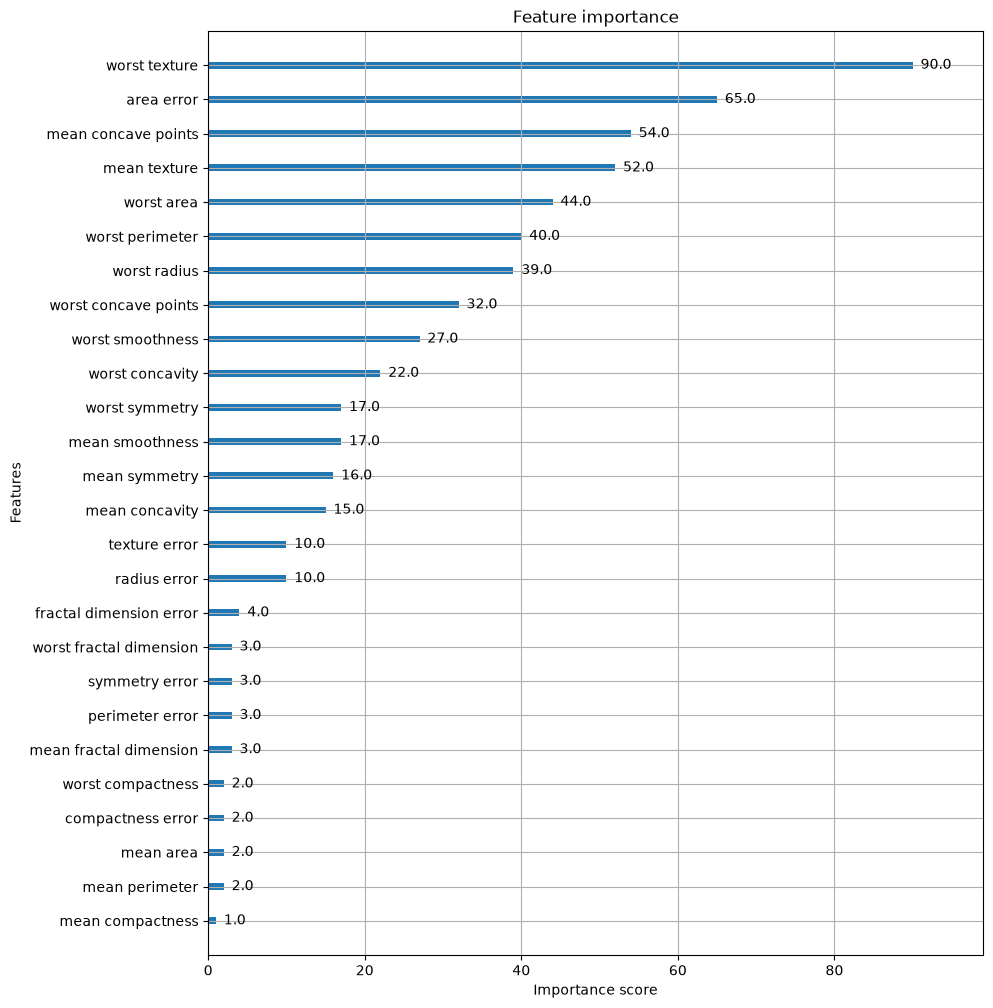

In [39]:
from ast import increment_lineno
from xgboost import plot_importance
import matplotlib.pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 12))
# 사이킷런 래퍼 클래스를 입력해도 무방.
plot_importance(xgb_wrapper, ax=ax)